In [3]:
%load_ext autoreload
%autoreload 2

In [18]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from collections import Counter
import numpy as np
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from part1.analysis import BenavoliCorrelatedT

REPO_ROOT = Path(r"D:\UvA\NLP\nlp1-group15")
sys.path.insert(0, str(REPO_ROOT))


from part1.experiment import cross_validation_experiment
import smlp2
from sklearn.metrics import precision_recall_fscore_support
sys.path.insert(0, r"D:\UvA\NLP\nlp1-group15\deliverable_1")
from sst2 import *

In [8]:
train, validation, test = load_sst2()

print(CLASSES)
print("train:", len(train))
print("validation:", len(validation))
print("test:", len(test))
print(train[2])

0: negative, 1: positive
train: 67349
validation: 872
test: 1821
('that loves its characters and communicates something rather beautiful about human nature ', 1)


In [9]:
tokenizer = get_tokenizer(train)

In [38]:
METRICS_DIR = Path("results")
device = "cuda"

selected_encoders = ["bow", "token-indicator", "tfidf"]
model_name = "mlp"

hidden_dim = 128
hidden_dim2 = 128
dropout = 0.1
learning_rate = 0.001
max_iter = 1000

encoder_classes = {
    "bow": BagOfWords,
    "token-indicator": TokenIndicator,
    "tfidf": TFIDFunigram,
}

cv_sets = get_cv_splits(train)
model_key = model_name
if "results" not in globals():
    results = {}
if "encoders" not in globals():
    encoders = {}

for encoder_name in selected_encoders:
    encoder_class = encoder_classes[encoder_name]

    results.setdefault(encoder_name, {})
    encoders.setdefault(encoder_name, {})
    results[encoder_name][model_key] = {}

    print(f"\nEncoder: {encoder_name} | Model: {model_key}")

    for fold, split in cv_sets[0].items():
        encoder = encoder_class(tokenizer)

        if encoder_name == "tfidf":
            encoder.fit([text for text, _ in split["training"]])

        encoders[encoder_name][fold] = encoder

        save_dir = f"results/{encoder_name}-{model_key}/seed-0"
        folder = Path(save_dir) / f"fold-{fold}"
        folder.mkdir(parents=True, exist_ok=True)

        if model_name == "mlp2":
            metrics, best_epoch, predictions = (
                smlp2.train_neural_network_model(
                    training_set=split["training"],
                    validation_set=split["validation"],
                    num_classes=len(CLASSES),
                    encoder=encoder,
                    save_to=str(folder / "model"),
                    hidden_dim=hidden_dim,
                    hidden_dim2=hidden_dim2,
                    dropout=dropout,
                    learning_rate=learning_rate,
                )
            )

            fold_result = {
                "models": {fold: str(folder / "model")},
                "predictions": {fold: predictions},
                "accuracies": {
                    fold: metrics[best_epoch]["val_metrics"]["accuracy"]
                },
            }
        else:
            fold_result = cross_validation_experiment(
                data_splits={fold: split},
                outcome_space=CLASSES,
                encoder=encoder,
                model_option=model_name,
                save_to=save_dir,
                loglin_args={"max_iter": max_iter},
                smlp_args={
                    "hidden_dim": hidden_dim,
                    "dropout": dropout,
                    "learning_rate": learning_rate,
                },
            )

        y_true = [label for _, label in split["validation"]]
        y_pred = fold_result["predictions"][fold]

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )

        fold_result["precisions"] = {fold: precision}
        fold_result["recalls"] = {fold: recall}
        fold_result["f1_scores"] = {fold: f1}
        results[encoder_name][model_key][fold] = fold_result
        print(f"Fold {fold}: {fold_result['accuracies'][fold]:.2%}")

    accuracies = [
        result["accuracies"][fold]
        for fold, result in results[encoder_name][model_key].items()
    ]
    print(f"Mean accuracy: {np.mean(accuracies):.2%}")

rows = []

for encoder_name, models in results.items():
    for model_name, folds in models.items():
        for fold, result in folds.items():
            rows.append({
                "Encoder": encoder_name,
                "Model": model_name,
                "Fold": fold,
                "Accuracy": result["accuracies"][fold],
                "Precision": result["precisions"][fold],
                "Recall": result["recalls"][fold],
                "F1": result["f1_scores"][fold],
            })

metrics = pd.DataFrame(rows)

metrics_path = METRICS_DIR / "cv_metrics.csv"

if metrics_path.exists():
    previous = pd.read_csv(metrics_path)
    metrics = pd.concat([previous, metrics], ignore_index=True)

metrics = metrics.drop_duplicates(
    subset=["Encoder", "Model", "Fold"],
    keep="last",
)

METRICS_DIR.mkdir(parents=True, exist_ok=True)
metrics.to_csv(metrics_path, index=False)



Encoder: bow | Model: mlp


  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 47.194 seconds
Dataloader done! Time taken: 1.172 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3776 | train acc: 0.8301 | val loss: 0.2697 | val acc: 0.8896
Epoch 02 | train loss: 0.2224 | train acc: 0.9126 | val loss: 0.2308 | val acc: 0.9082
Epoch 03 | train loss: 0.1607 | train acc: 0.9392 | val loss: 0.2193 | val acc: 0.9175
Epoch 04 | train loss: 0.1207 | train acc: 0.9557 | val loss: 0.2265 | val acc: 0.9190
Epoch 05 | train loss: 0.0931 | train acc: 0.9666 | val loss: 0.2378 | val acc: 0.9234
Epoch 06 | train loss: 0.0755 | train acc: 0.9736 | val loss: 0.2373 | val acc: 0.9261
Epoch 07 | train loss: 0.0617 | train acc: 0.9790 | val loss: 0.2469 | val acc: 0.9271
Epoch 08 | train loss: 0.0520 | train acc: 0.9821 | val loss: 0.2644 | val acc: 0.9271
Epoch 09 | train loss: 0.0458 | train acc: 0.9857 | val loss: 0.2698 | val acc: 0.9281
Epoch 10 | train loss: 0.0397 | train acc: 0.9872 | val loss: 0.2766 | val acc: 0.9292
Epoch 11 | train loss: 0.0359 | train acc: 0.9882 | val loss: 0.2935 | val acc: 0.9297
Epoch 12 | train loss: 0.0334 | train acc: 

  0%|          | 0/1 [00:00<?, ?it/s]

... (51 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.641 seconds
Dataloader done! Time taken: 1.074 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3858 | train acc: 0.8215 | val loss: 0.2981 | val acc: 0.8727
Epoch 02 | train loss: 0.2564 | train acc: 0.8935 | val loss: 0.2702 | val acc: 0.8879
Epoch 03 | train loss: 0.2119 | train acc: 0.9155 | val loss: 0.2577 | val acc: 0.8998
Epoch 04 | train loss: 0.1719 | train acc: 0.9345 | val loss: 0.2506 | val acc: 0.9100
Epoch 05 | train loss: 0.1343 | train acc: 0.9514 | val loss: 0.2507 | val acc: 0.9143
Epoch 06 | train loss: 0.1030 | train acc: 0.9643 | val loss: 0.2574 | val acc: 0.9168
Epoch 07 | train loss: 0.0789 | train acc: 0.9734 | val loss: 0.2697 | val acc: 0.9193
Epoch 08 | train loss: 0.0625 | train acc: 0.9789 | val loss: 0.2851 | val acc: 0.9204
Epoch 09 | train loss: 0.0511 | train acc: 0.9824 | val loss: 0.2957 | val acc: 0.9229
Epoch 10 | train loss: 0.0440 | train acc: 0.9849 | val loss: 0.3119 | val acc: 0.9210
Epoch 11 | train loss: 0.0389 | train acc: 0.9864 | val loss: 0.3229 | val acc: 0.9228
Epoch 12 | train loss: 0.0335 | train acc: 

<h1>Metrics<h1>

In [41]:
metrics = pd.read_csv(METRICS_DIR / "cv_metrics.csv")

display(
    metrics.groupby(["Model", "Encoder"])[
        ["Accuracy", "Precision", "Recall", "F1"]
    ].mean().style.format("{:.2%}")
)

<h1>Evaluation<h1>

Metric: F1 | ROPE: ±0.005
A: tfidf-mlp
B: tfidf-mlp2
P(A practical better): 0.5%
P(practical even):  33.1%
P(B practical better): 66.4%


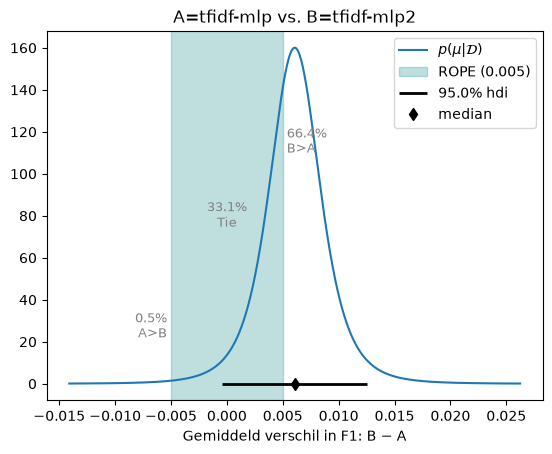

In [42]:
encoder_a, model_a = 'tfidf', 'mlp'
encoder_b, model_b = 'tfidf', 'mlp2'
metric = "F1"
rope = 0.005

name_a = f"{encoder_a}-{model_a}"
name_b = f"{encoder_b}-{model_b}"

a = metrics.loc[
    (metrics["Encoder"] == encoder_a)
    & (metrics["Model"] == model_a),
    ["Fold", metric],
]

b = metrics.loc[
    (metrics["Encoder"] == encoder_b)
    & (metrics["Model"] == model_b),
    ["Fold", metric],
]

paired = a.merge(
    b,
    on="Fold",
    suffixes=("_a", "_b"),
    validate="one_to_one",
).sort_values("Fold")

posterior = BenavoliCorrelatedT(
    paired[f"{metric}_a"].to_numpy(),
    paired[f"{metric}_b"].to_numpy(),
    runs=1,
    names=[name_a, name_b],
)

p_a, p_tie, p_b = posterior.probs(rope)

print(f"Metric: {metric} | ROPE: ±{rope:.3f}")
print(f"A: {name_a}")
print(f"B: {name_b}")
print(f"P(A practical better): {p_a:.1%}")
print(f"P(practical even):  {p_tie:.1%}")
print(f"P(B practical better): {p_b:.1%}")

fig, ax = posterior.plot(rope_param=rope)
ax.set_xlabel(f"Gemiddeld verschil in {metric}: B − A")
plt.show()